# TFP shock with sticky wages: the planner's problem

The nominal-rate sequence is chosen to **maximise household utility** rather than to
minimise the output gap. Two scenarios:

1. **No time to build** — every firm reprices immediately.
2. **Exogenous time to build** — firms reprice with the calibrated lag $\tau$.

Companion to `A_shock_gap.ipynb`, which minimises $\sum_t x_t^2$ instead.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_6325/2363727927.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


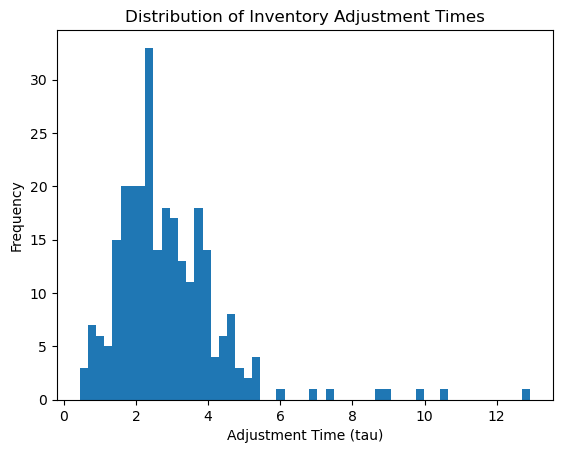

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
DAYS_PER_MONTH = 30
TAX_RATE = 0.1
HISTOGRAM_BINS = 55

data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = (data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (DAYS_PER_MONTH * TAX_RATE))

plt.hist(data_tau, bins=HISTOGRAM_BINS)
plt.title('Distribution of Inventory Adjustment Times')
plt.xlabel('Adjustment Time (tau)'); plt.ylabel('Frequency')
plt.show()

In [3]:
NOMINAL_INTEREST_RATE = 0.01
INVENTORY_DURATION = 30
ADJUSTMENT_RATE = 0.9

beta = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(INVENTORY_DURATION /
                                                  (INVENTORY_TO_COGS_SCALING * ADJUSTMENT_RATE)))
beta_hh = beta
W = 1
sigma = 5                      # CES elasticity across firms

gamma = 2.0                    # relative risk aversion / IS slope
eta = 2.0                      # inverse Frisch elasticity
PHI_YA = (1 + eta) / (gamma + eta)
rho = 1 / beta_hh - 1

markup = sigma / (sigma - 1)

# Does a subsidy offset the monopolistic markup, making the steady state efficient?
# True  -> chi = 1      : steady state is first best; the planner only stabilises.
# False -> chi = 1/mu   : steady state is too small, so the planner ALSO wants to expand.
#                         That is a FIRST-ORDER effect and it swamps stabilisation.
SUBSIDY_OFFSETS_MARKUP = True
chi = 1.0 if SUBSIDY_OFFSETS_MARKUP else 1.0 / markup
chi_alt = 1.0 / markup if SUBSIDY_OFFSETS_MARKUP else 1.0

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA:.4f}')
print(f'markup={markup:.4f}, chi={chi:.4f}  (N_ss = C_ss = A_ss = 1)')
print(f'efficient N at this chi: {chi**(-1/(gamma+eta)):.4f}   '
      f'(1.0000 => steady state is first best)')

gamma=2.0, eta=2.0, phi_ya=0.7500
markup=1.2500, chi=1.0000  (N_ss = C_ss = A_ss = 1)
efficient N at this chi: 1.0000   (1.0000 => steady state is first best)


In [4]:
EPSILON = 1e-10
tau_diff = np.zeros((1000, 1))

for i, c in enumerate(np.linspace(0, 0.99, 1000)):
    if beta * c <= EPSILON or beta1 * c <= EPSILON:
        tau_diff[i] = np.inf
        continue
    N = -(data_tau) - 1 / np.log(beta * c)
    tau1 = -1 / np.log(beta * c) - N;   tau1[tau1 < 0] = 0
    tau2 = -1 / np.log(beta1 * c) - N;  tau2[tau2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(tau1 - tau2))

c_list = np.linspace(0, 0.99, 1000)
optimal_c_value = c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]]
print('optimal c:', optimal_c_value)

optimal c: [0.9018018]


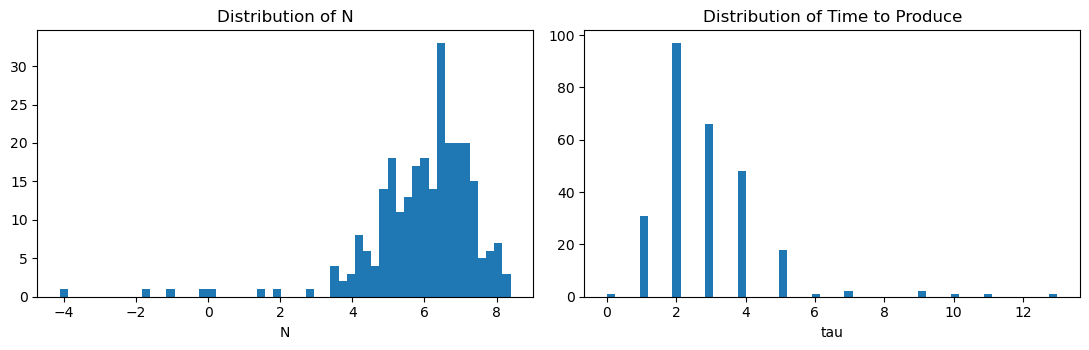

In [5]:
N = -data_tau - 1/np.log(beta_hh * optimal_c_value)
tau = -1/np.log(beta_hh * optimal_c_value) - N
tau[tau < 0] = 0
tau_floor, tau_ceil = np.floor(tau), np.ceil(tau)
tprod_ceil = (beta_hh * optimal_c_value)**tau_ceil * (tau_ceil + N)
tprod_floor = (beta_hh * optimal_c_value)**tau_floor * (tau_floor + N)
tau[(tprod_ceil - tprod_floor) > 0] = tau_ceil[(tprod_ceil - tprod_floor) > 0]
tau[(tprod_ceil - tprod_floor) < 0] = tau_floor[(tprod_ceil - tprod_floor) < 0]
tau[tau < 0] = 0

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(N, bins=HISTOGRAM_BINS); ax[0].set_title('Distribution of N'); ax[0].set_xlabel('N')
ax[1].hist(tau, bins=HISTOGRAM_BINS); ax[1].set_title('Distribution of Time to Produce')
ax[1].set_xlabel('tau')
plt.tight_layout(); plt.show()

In [6]:
def generate_pattern_array_with_extra_rows(tau):
    """Staggering matrix: which firms have re-optimised by period t (shock factor 0.97)."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing_count = len(set(range(int(max(tau)) + 1)) - set(tau))

    A = np.ones((m + 2, n + missing_count), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms_adjusting = tau[tau == i - 1]
        for j in range(len(firms_adjusting)):
            A[i, n - i - j - count] = 0.97
        if len(firms_adjusting) > 1:
            count += len(firms_adjusting) - 1

    A_extended = np.vstack([A, np.ones(n + missing_count, dtype=float)])
    return A_extended[:, 0:n - int(np.min(tau))]

## 2. The IS curve

The allocation for any rate path comes from the same gap-form IS curve as in
`A_shock_gap.ipynb`; the planner's objective is what changes.

$$x_t = x_{t+1} - \frac{1}{\gamma}\bigl(i_t - \pi_{t+1} - r^n_t\bigr), \qquad
  y_t = x_t + y^n_t, \qquad n_t = y_t - a_t$$

In [7]:
def euler_path_gap(i_path, a_level, gamma=2.0, eta=2.0, beta_hh=1/(1+0.01), a_prev=0.0):
    """IS curve in output-gap form.  Returns (x, pi, y_nat, r_nat)."""
    i_path = np.asarray(i_path, float)
    a_level = np.asarray(a_level, float)
    T = len(i_path)
    rho = 1.0 / beta_hh - 1.0
    phi_ya = (1.0 + eta) / (gamma + eta)

    da = np.empty(T)
    da[0] = a_level[0] - a_prev
    da[1:] = a_level[1:] - a_level[:-1]
    pi = -da

    y_nat = phi_ya * a_level
    dy_nat_fwd = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho + gamma * dy_nat_fwd
    pi_fwd = np.r_[pi[1:], 0.0]

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (i_path[t] - pi_fwd[t] - r_nat[t])

    return x[:T], pi, y_nat, r_nat

## 3. The planner's objective

The planner picks the nominal-rate sequence that **maximises household utility**

$$U = \sum_{t=0}^{T-1}\beta^t\Bigl[\frac{C_t^{1-\gamma}}{1-\gamma}
      - \chi\frac{N_t^{1+\eta}}{1+\eta}\Bigr]$$

evaluated on the model's own paths, rather than minimising an ad-hoc quadratic loss.
Given the log deviations $y_t$ and $a_t$:

$$C_t = e^{y_t} \quad (C=Y), \qquad N_t = e^{y_t-a_t} \quad (y = a + n)$$

$\chi$ is pinned down by the steady-state labour FOC. At the monopolistically competitive
steady state the real wage is $1/\mathcal{M}$ with $\mathcal{M}=\sigma/(\sigma-1)$, and
normalising $A=C=N=1$ gives $\chi = 1/\mathcal{M} = (\sigma-1)/\sigma$. Note this steady
state is **not** the first best: the markup makes $N_{ss}$ too low, so the planner here is
a constrained one — it chooses rates taking the markup and the wage rigidity as given.

Welfare differences are reported as a **consumption equivalent** $\lambda$: the permanent
percentage of steady-state consumption that would have to be added to the no-policy-change
path to make it as good as the alternative.

Each experiment also reports the gap-minimising sequence from the companion notebook, so
the two objectives can be compared directly.

In [8]:
def welfare(y_path, a_path, gamma, eta, beta_hh, chi, xi_log=None):
    """
    Discounted household utility along a model path.

        U = sum_t beta^t * xi_t * [ C_t^(1-gamma)/(1-gamma) - chi * N_t^(1+eta)/(1+eta) ]

    y_path, a_path are LOG DEVIATIONS from a steady state normalised to A=C=N=1, so

        C_t = exp(y_t)                      goods market clearing, C = Y
        N_t = exp(y_t - a_t)                production function y = a + n

    xi_log is the log preference shifter (None -> xi = 1 throughout).
    Returns (U, U_consumption_part, U_labour_part).
    """
    y_path = np.asarray(y_path, float)
    a_path = np.asarray(a_path, float)
    T = len(y_path)
    disc = beta_hh ** np.arange(T)
    if xi_log is not None:
        disc = disc * np.exp(np.asarray(xi_log, float))

    C = np.exp(y_path)
    Nl = np.exp(y_path - a_path)

    u_c = C**(1 - gamma) / (1 - gamma)
    u_n = chi * Nl**(1 + eta) / (1 + eta)
    return np.sum(disc * (u_c - u_n)), np.sum(disc * u_c), np.sum(disc * u_n)


def cons_equivalent(U_alt, UC_base, UN_base, gamma):
    """
    Permanent consumption supplement lambda that makes the BASELINE path as good as
    the alternative:  sum beta^t [((1+l)C_b)^(1-g)/(1-g)] - UN_base = U_alt.
    Returns lambda (0.01 = 1 percent of steady-state consumption).
    """
    ratio = (U_alt + UN_base) / UC_base
    return ratio**(1.0 / (1.0 - gamma)) - 1.0


def summarise_planner(label, U, r_arrange, matches, r_choice, X_gap, dev_gap,
                      UC, UN, gamma, U_alt=None, alt_label=''):
    """Standard summary: utility-optimal vs gap-optimal vs no policy change."""
    U = np.asarray(U).ravel()
    dev_gap = np.asarray(dev_gap).ravel()
    best_u = int(np.argmax(U))                 # planner: MAXIMISE utility
    best_x = int(np.argmin(dev_gap))           # gap-minimising benchmark
    base = int(np.where(matches)[0][0])
    w = 46
    lam_u = cons_equivalent(U[best_u], UC[base], UN[base], gamma)
    lam_x = cons_equivalent(U[best_x], UC[base], UN[base], gamma)
    print('=' * 74)
    print(label)
    print('=' * 74)
    print(f'{"utility, no policy change":<{w}}: {U[base]:.10f}')
    print(f'{"utility, utility-maximising policy":<{w}}: {U[best_u]:.10f}')
    print(f'{"utility, gap-minimising policy":<{w}}: {U[best_x]:.10f}')
    print()
    print(f'{"welfare gain, utility-max (cons. equiv.)":<{w}}: {100*lam_u:+.6f}% of ss C')
    print(f'{"welfare gain, gap-min   (cons. equiv.)":<{w}}: {100*lam_x:+.6f}% of ss C')
    print()
    print(f'{"rate sequence, no policy change":<{w}}: {np.round(r_arrange[base], 6)}')
    print(f'{"rate sequence, utility-maximising":<{w}}: {np.round(r_arrange[best_u], 6)}')
    print(f'{"rate sequence, gap-minimising":<{w}}: {np.round(r_arrange[best_x], 6)}')
    print(f'{"utility-max and gap-min coincide":<{w}}: {best_u == best_x}')
    if U_alt is not None:
        alt = int(np.argmax(np.asarray(U_alt).ravel()))
        print(f'{"rate sequence, " + alt_label:<{w}}: {np.round(r_arrange[alt], 6)}')
        print(f'{"  ... same choice as the baseline":<{w}}: {alt == best_u}')
    print()
    print(f'{"peak |x_t|, no policy change":<{w}}: {np.max(np.abs(X_gap[base])):.4e}')
    print(f'{"peak |x_t|, utility-maximising":<{w}}: {np.max(np.abs(X_gap[best_u])):.4e}')
    on_bound = bool(np.any(np.isclose(r_arrange[best_u], r_choice[0]) |
                           np.isclose(r_arrange[best_u], r_choice[-1])))
    print(f'{"grid":<{w}}: {len(r_choice)} points on '
          f'[{r_choice[0]:g}, {r_choice[-1]:g}]')
    print(f'{"optimum sits on a grid bound":<{w}}: {on_bound}')
    if on_bound:
        print('   -> the optimum may not be interior; widen r_choice to check.')
    return best_u, best_x, base


def planner_figure(label, X_gap, I_path, best_u, best_x, base, fname, horizon=20):
    """Two panels on a common horizon: the output gap and the nominal rate."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    t = np.arange(horizon)

    axes[0].plot(t, X_gap[base][:horizon], lw=2, label='no policy change')
    axes[0].plot(t, X_gap[best_u][:horizon], '--', lw=2, label='utility-maximising policy')
    if best_x != best_u:
        axes[0].plot(t, X_gap[best_x][:horizon], ':', lw=2, label='gap-minimising policy')
    axes[0].axhline(0, color='k', lw=0.8)
    axes[0].set_xlabel('Time'); axes[0].set_ylabel('$x_t = y_t - y^n_t$')
    axes[0].set_xlim(0, horizon - 1)
    axes[0].set_title('Output gap')
    axes[0].legend(fontsize=8)

    axes[1].step(t, I_path[base][:horizon], where='post', lw=2, label='no policy change')
    axes[1].step(t, I_path[best_u][:horizon], where='post', linestyle='--', lw=2,
                 label='utility-maximising policy')
    if best_x != best_u:
        axes[1].step(t, I_path[best_x][:horizon], where='post', linestyle=':', lw=2,
                     label='gap-minimising policy')
    axes[1].set_xlabel('Time'); axes[1].set_ylabel('$i_t$')
    axes[1].set_xlim(0, horizon - 1)
    axes[1].set_title('Nominal interest rate')
    axes[1].legend(fontsize=8)

    fig.suptitle(label, fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

## 4. Planner's problem: no time to build

Aggregate TFP is the shock itself: a one-time $-1\%$ level drop at $t=0$.

In [9]:
T = 10
sequence_length = 5
r_choice = np.linspace(0, 0.0125, 6)
r_arrange = np.array(list(itertools.product(r_choice, repeat=sequence_length)))
size = r_arrange.shape[0]

U_total = np.zeros(size)
U_cons = np.zeros(size)
U_lab = np.zeros(size)
U_chi_alt = np.zeros(size)          # the other steady-state calibration
deviation_gap = np.zeros(size)
X_gap = np.zeros((size, T))
Y_output = np.zeros((size, T))
I_path_store = np.zeros((size, T))
C_path = np.zeros((size, T))
N_path = np.zeros((size, T))

for k, r_vec in enumerate(r_arrange):
    i_path = np.full(T, rho, dtype=float)
    i_path[:sequence_length] = r_vec

    a_level = np.zeros(T, dtype=float)
    a_level[0] = -0.01                      # 1 percent decrease in A

    x, pi, y_nat, r_nat = euler_path_gap(i_path, a_level, gamma=gamma, eta=eta,
                                         beta_hh=beta_hh, a_prev=0.0)
    y = x + y_nat

    U, Uc, Un = welfare(y, a_level, gamma, eta, beta_hh, chi)
    Uca, _, _ = welfare(y, a_level, gamma, eta, beta_hh, chi_alt)

    U_total[k], U_cons[k], U_lab[k] = U, Uc, Un
    U_chi_alt[k] = Uca
    deviation_gap[k] = np.sum(x**2)
    X_gap[k] = x
    Y_output[k] = y
    I_path_store[k] = i_path
    C_path[k] = np.exp(y)
    N_path[k] = np.exp(y - a_level)

matches = np.all(np.isclose(r_arrange, rho), axis=1)
bu_ntb, bx_ntb, base_ntb = summarise_planner(
    '1 percent decrease in A -- No time to build',
    U_total, r_arrange, matches, r_choice, X_gap, deviation_gap, U_cons, U_lab, gamma,
    U_alt=U_chi_alt, alt_label='under the other steady state')

1 percent decrease in A -- No time to build
utility, no policy change                     : -12.7647403104
utility, utility-maximising policy            : -12.7647307868
utility, gap-minimising policy                : -12.7647307868

welfare gain, utility-max (cons. equiv.)      : +0.000100% of ss C
welfare gain, gap-min   (cons. equiv.)        : +0.000100% of ss C

rate sequence, no policy change               : [0.01 0.01 0.01 0.01 0.01]
rate sequence, utility-maximising             : [0.0125 0.0125 0.01   0.01   0.01  ]
rate sequence, gap-minimising                 : [0.0125 0.0125 0.01   0.01   0.01  ]
utility-max and gap-min coincide              : True
rate sequence, under the other steady state   : [0. 0. 0. 0. 0.]
  ... same choice as the baseline             : False

peak |x_t|, no policy change                  : 2.5000e-03
peak |x_t|, utility-maximising                : 1.2500e-03
grid                                          : 6 points on [0, 0.0125]
optimum sits on a grid 

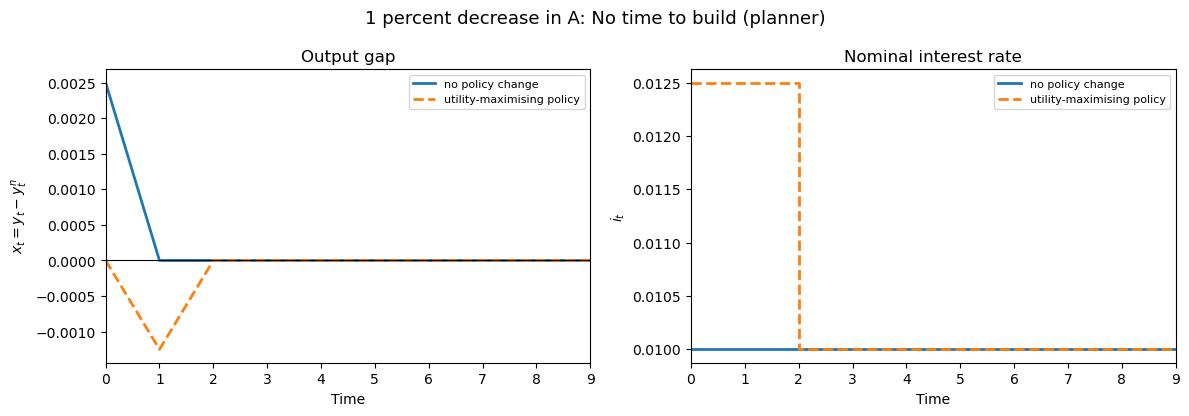

In [10]:
planner_figure('1 percent decrease in A: No time to build (planner)',
               X_gap, I_path_store, bu_ntb, bx_ntb, base_ntb,
               '../semi_endo_A_planner_no_time_to_build.png', horizon=10)

## 5. Planner's problem: exogenous time to build

Firms reprice with the calibrated lag $\tau$, so $a_t$ follows the staggered CES index and
is itself rate-dependent.

In [11]:
T = 30
sequence_length = 4
r_choice = np.linspace(0, 0.0125, 6)
r_arrange = np.array(list(itertools.product(r_choice, repeat=sequence_length)))
size = r_arrange.shape[0]

U_total = np.zeros(size)
U_cons = np.zeros(size)
U_lab = np.zeros(size)
U_chi_alt = np.zeros(size)          # the other steady-state calibration
deviation_gap = np.zeros(size)
X_gap = np.zeros((size, T))
Y_output = np.zeros((size, T))
I_path_store = np.zeros((size, T))
A_bar_store = np.zeros((size, T))

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
A_pattern = generate_pattern_array_with_extra_rows(tau)

for k in range(size):
    n = sequence_length
    r = np.asarray(r_arrange[k], dtype=float)

    interest_rate_list = np.ones((T, T)) * rho
    arr2d = np.full((n, n), rho, dtype=float)
    for i in range(n):
        arr2d[i, :i+1] = r[i::-1]
    interest_rate_list[0:n, :n] = arr2d

    beta_mat = 1.0 / (1.0 + interest_rate_list)
    cumprod_ext = np.ones((T, T + 1))
    cumprod_ext[:, 1:] = np.cumprod(beta_mat, axis=1)
    beta_prod = cumprod_ext[:, tvals]

    tprod_array = np.array((beta_prod * optimal_c_value) *
                           ((tvals + N_array) * np.ones((T, 269))))
    prod_shock = np.ones((T, 269))
    prod_shock[0:15] = A_pattern[1:]
    A_prod = np.sum((prod_shock * tprod_array)**(sigma - 1), axis=1)**(1/(sigma - 1))

    i_path = np.ones(T) * rho
    i_path[0:sequence_length] = r_arrange[k]
    abar = np.log(A_prod) - np.log(A_prod)[-1]

    x, pi, y_nat, r_nat = euler_path_gap(i_path, abar, gamma=gamma, eta=eta,
                                         beta_hh=beta_hh, a_prev=0)
    y = x + y_nat

    U, Uc, Un = welfare(y, abar, gamma, eta, beta_hh, chi)
    Uca, _, _ = welfare(y, abar, gamma, eta, beta_hh, chi_alt)

    U_total[k], U_cons[k], U_lab[k] = U, Uc, Un
    U_chi_alt[k] = Uca
    deviation_gap[k] = np.sum(x**2)
    X_gap[k] = x
    Y_output[k] = y
    I_path_store[k] = i_path
    A_bar_store[k] = abar

matches = np.all(np.isclose(r_arrange, rho), axis=1)
bu_ttb, bx_ttb, base_ttb = summarise_planner(
    '3 percent decrease in A -- Exogenous time to build',
    U_total, r_arrange, matches, r_choice, X_gap, deviation_gap, U_cons, U_lab, gamma,
    U_alt=U_chi_alt, alt_label='under the other steady state')

3 percent decrease in A -- Exogenous time to build
utility, no policy change                     : -34.7826078319
utility, utility-maximising policy            : -34.7062079228
utility, gap-minimising policy                : -34.7726212979

welfare gain, utility-max (cons. equiv.)      : +0.293807% of ss C
welfare gain, gap-min   (cons. equiv.)        : +0.038307% of ss C

rate sequence, no policy change               : [0.01 0.01 0.01 0.01]
rate sequence, utility-maximising             : [0. 0. 0. 0.]
rate sequence, gap-minimising                 : [0.0075 0.0075 0.01   0.0125]
utility-max and gap-min coincide              : False
rate sequence, under the other steady state   : [0. 0. 0. 0.]
  ... same choice as the baseline             : True

peak |x_t|, no policy change                  : 2.6399e-03
peak |x_t|, utility-maximising                : 1.7539e-02
grid                                          : 6 points on [0, 0.0125]
optimum sits on a grid bound                  : True
 

### Why the planner goes to the corner here

Unlike the no-time-to-build case, the utility optimum below is the **lowest rate on the
grid**, and it does *not* coincide with the gap optimum. That is the model, not a bug.

Firm output is $\text{tprod}_i = \beta^{\tau_i} c\,(\tau_i + N_i)$ with
$\beta = 1/(1+i)$: the nominal rate is a *cost of production* applied over the lag
$\tau_i$. So a permanent rate cut raises measured productivity by roughly
$\bar\tau\times(\text{the cut})$ — a **first-order level gain** with nothing in the
model to offset it. Exact utility picks that up; the quadratic gap objective, which only
sees deviations from potential, cannot.

Read the corner as a diagnostic: within this model monetary policy has a free, permanent
productivity lever, so "maximise utility" degenerates to "cut to the bound". If that is
not intended, the rate needs a cost somewhere (a resource cost of the lag, or firms
discounting at a rate policy does not control).

In [12]:
# --- size of the rate -> productivity channel --------------------------------
CVAL = optimal_c_value
probe = {}
for i_lvl in [0.0, rho]:
    irl = np.ones((T, T)) * i_lvl
    ce = np.ones((T, T + 1)); ce[:, 1:] = np.cumprod(1/(1 + irl), axis=1)
    bp = ce[:, tvals]
    tp = (bp * CVAL) * ((tvals + N_array) * np.ones((T, 269)))
    probe[i_lvl] = np.sum(tp**(sigma - 1), axis=1)**(1/(sigma - 1))

gain = float(np.log(probe[0.0][0] / probe[rho][0]))
print(f'mean tau                                  : {float(tau.mean()):.3f} periods')
print(f'cutting i from rho={rho:.4f} to 0 raises A by : {100*gain:.4f}%')
print(f'compare  mean(tau) * rho                  : {100*float(tau.mean())*rho:.4f}%')

mean tau                                  : 2.888 periods
cutting i from rho=0.0100 to 0 raises A by : 2.8759%
compare  mean(tau) * rho                  : 2.8885%


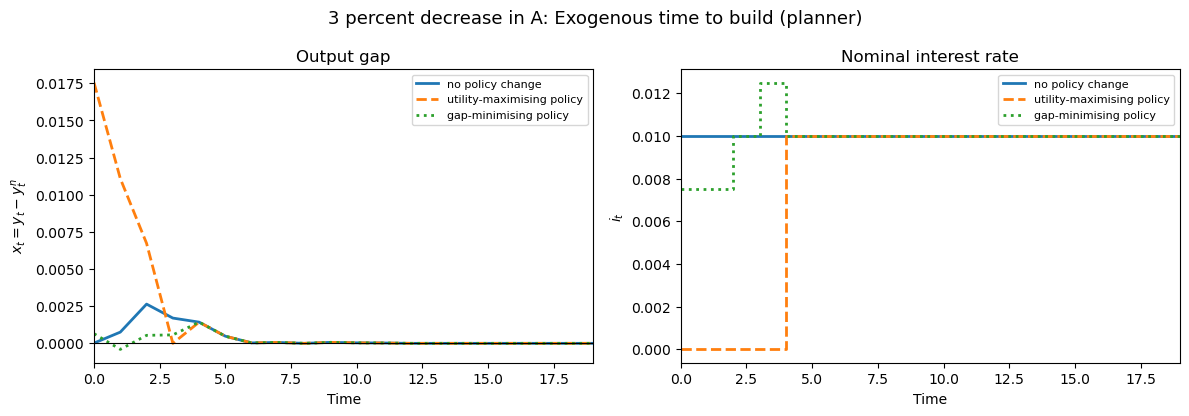

In [13]:
planner_figure('3 percent decrease in A: Exogenous time to build (planner)',
               X_gap, I_path_store, bu_ttb, bx_ttb, base_ttb,
               '../semi_endo_A_planner_exogenous_time_to_build.png', horizon=20)

## Escalating the policy horizon

Every optimum above sits on a bound of `r_choice`, which means the answer is being shaped
by the grid and by the short window of policy freedom rather than by the economics. This
section grows the number of free periods $L$ — everything after $L$ stays pinned at $\rho$
— and re-solves, stopping when the **last free period comes back to $\rho$**. At that
point the horizon is long enough that pinning the tail no longer binds.

Grid enumeration is $6^L$ and blows up immediately, so this uses a bounded continuous
solve (L-BFGS-B on $[0,\,0.05]$, the lower bound being the ZLB) instead of enumerating.

In [14]:
from scipy.optimize import minimize


def escalate(objective, T, L_start=3, L_max=16, tol=1e-4, bounds=(0.0, 0.05)):
    """
    Grow the number of free policy periods L until the optimal sequence's LAST free
    period returns to rho.  `objective(r_vec, T)` is MINIMISED (pass -utility for the
    planner problems).  Returns (history, settled_L); settled_L is None if it never
    settles by L_max.
    """
    hist = []
    print(f'{"L":>3} {"last i_t":>10} {"settled":>8} {"objective":>15}   optimal sequence')
    print('-' * 92)
    for L in range(L_start, L_max + 1):
        res = minimize(lambda r: objective(r, T), np.ones(L) * rho,
                       method='L-BFGS-B', bounds=[bounds] * L,
                       options={'maxiter': 20000, 'ftol': 1e-18, 'gtol': 1e-14})
        settled = bool(np.isclose(res.x[-1], rho, atol=tol))
        hist.append((L, res.x.copy(), float(res.fun), settled))
        print(f'{L:>3} {res.x[-1]:>10.6f} {str(settled):>8} {res.fun:>15.6e}   '
              f'{np.round(res.x[:8], 5)}{" ..." if L > 8 else ""}')
        if settled:
            print(f'\n-> settles at L = {L}: the last free period is back at '
                  f'rho = {rho:.4f}')
            return hist, L
    print(f'\n-> NOT settled by L = {L_max}: the optimum is still away from rho.')
    return hist, None


def escalate_figure(hist, settled_L, label, fname):
    """Objective against L, and the rate path at the final L."""
    Ls = [h[0] for h in hist]
    objs = [h[2] for h in hist]
    r_last = hist[-1][1]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(Ls, objs, 'o-')
    axes[0].set_yscale('symlog', linthresh=1e-18)
    axes[0].set_xlabel('free policy periods $L$'); axes[0].set_ylabel('objective')
    axes[0].set_title('Objective as the horizon grows')

    p = np.arange(len(r_last))
    axes[1].step(p, r_last, where='post', lw=2, label=f'optimal $i_t$ at L={Ls[-1]}')
    axes[1].axhline(rho, color='k', lw=0.8, linestyle='--', label=r'$\rho$')
    axes[1].set_xlabel('Period'); axes[1].set_ylabel('$i_t$')
    axes[1].set_title('Optimal rate path at the final $L$')
    axes[1].legend(fontsize=8)

    status = f'settles at L={settled_L}' if settled_L else 'does not settle'
    fig.suptitle(f'{label}  ({status})', fontsize=13)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

In [15]:
def tfp_from_rates(r, T):
    L = len(r)
    interest_rate_list = np.ones((T, T)) * rho
    arr2d = np.full((L, L), rho, dtype=float)
    for i in range(L):
        arr2d[i, :i+1] = np.asarray(r, float)[i::-1]
    interest_rate_list[0:L, :L] = arr2d
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0/(1.0 + interest_rate_list), axis=1)
    bp = ce[:, tvals]
    tp = (bp * optimal_c_value) * ((tvals + N_array) * np.ones((T, 269)))
    ps = np.ones((T, 269)); ps[0:15] = A_pattern[1:]
    A = np.sum((ps * tp)**(sigma - 1), axis=1)**(1/(sigma - 1))
    return np.log(A) - np.log(A)[-1]


def obj_u_ntb(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    a = np.zeros(T); a[0] = -0.01
    x, pi, y_nat, r_nat = euler_path_gap(ip, a, gamma=gamma, eta=eta,
                                         beta_hh=beta_hh, a_prev=0.0)
    return -welfare(x + y_nat, a, gamma, eta, beta_hh, chi)[0]


def obj_u_ttb(r, T):
    ip = np.ones(T) * rho; ip[:len(r)] = r
    a = tfp_from_rates(r, T)
    x, pi, y_nat, r_nat = euler_path_gap(ip, a, gamma=gamma, eta=eta,
                                         beta_hh=beta_hh, a_prev=0)
    return -welfare(x + y_nat, a, gamma, eta, beta_hh, chi)[0]


print('NO TIME TO BUILD')
hist_ntb, L_ntb = escalate(obj_u_ntb, 10, L_start=3, L_max=9)
print()
print('EXOGENOUS TIME TO BUILD')
hist_ttb, L_ttb = escalate(obj_u_ttb, 30, L_start=3, L_max=16)

NO TIME TO BUILD
  L   last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3   0.010000     True    1.276473e+01   [0.015 0.01  0.01 ]

-> settles at L = 3: the last free period is back at rho = 0.0100

EXOGENOUS TIME TO BUILD
  L   last i_t  settled       objective   optimal sequence
--------------------------------------------------------------------------------------------
  3   0.000000    False    3.473154e+01   [0. 0. 0.]
  4   0.000000    False    3.470621e+01   [0. 0. 0. 0.]
  5   0.000000    False    3.468053e+01   [0. 0. 0. 0. 0.]
  6   0.000000    False    3.465545e+01   [0. 0. 0. 0. 0. 0.]
  7   0.000000    False    3.463108e+01   [0. 0. 0. 0. 0. 0. 0.]
  8   0.000000    False    3.460741e+01   [0. 0. 0. 0. 0. 0. 0. 0.]
  9   0.000000    False    3.458455e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...
 10   0.000000    False    3.456264e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...
 11   0.000000    

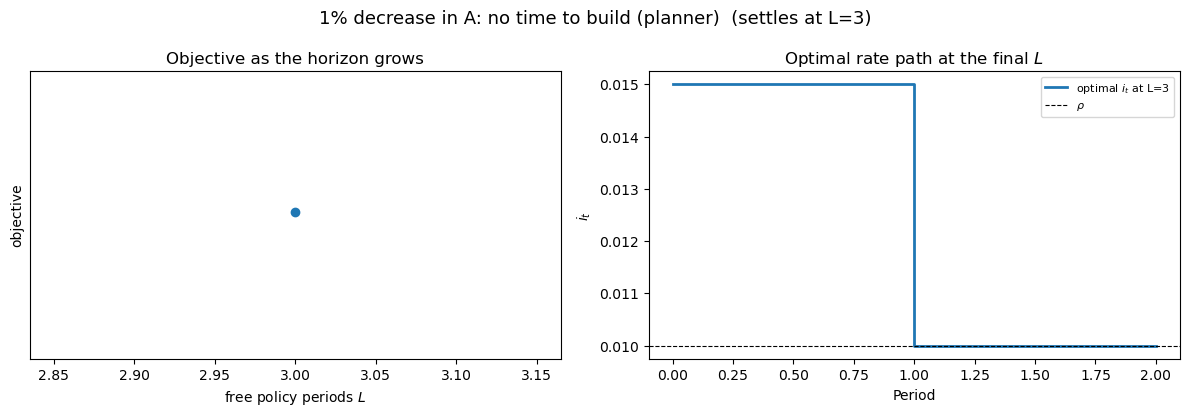

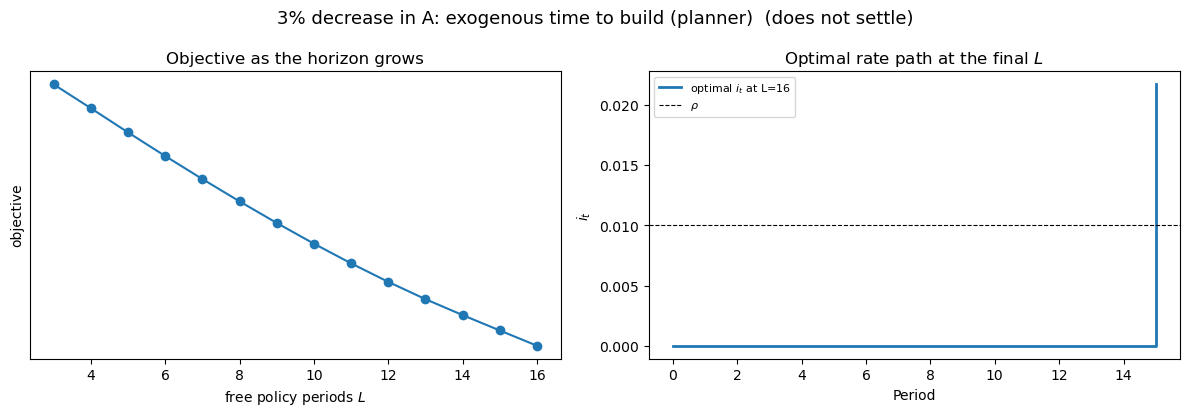

In [16]:
escalate_figure(hist_ntb, L_ntb, '1% decrease in A: no time to build (planner)',
                '../semi_endo_A_planner_escalate_no_time_to_build.png')
escalate_figure(hist_ttb, L_ttb, '3% decrease in A: exogenous time to build (planner)',
                '../semi_endo_A_planner_escalate_exogenous_time_to_build.png')